# m6A density around the stop codon and the PAS of shifting 3'UTRs

This notebook asks whether **RMBase m6A sites** are more frequent near the 3' end of 3'UTR pairs whose isoform usage shifts than in the other pairs, and whether the difference remains once the A content of the sequence is taken into account (m6A can only sit on an A). The last section shows the expression of the m6A machinery over MN differentiation.

**Groups of 3'UTR pairs** (MN_diff shift tables, `projects/ALS_Comp/MN_diff/results/3UTR_analysis/shifts/`), each compared with all the other pairs of `table_of_pairs.csv` (one pair per proximal isoform: the one with the longest distal isoform):
- lengthened from D22 to D35 in CTRL nuclei: `pairs_distals_D22_Nuclear_Wildtype_vs_D35_Nuclear_Wildtype.csv`;
- longer in the nucleus than in the cytoplasm at D35 in CTRL (proximal shift in the cytoplasm): `pairs_proximals_D35_Nuclear_Wildtype_vs_D35_Cytoplasmic_Wildtype.csv`;
- shortened in VCP vs CTRL nuclei at D35: `pairs_proximals_D35_Nuclear_Wildtype_vs_D35_Nuclear_VCP.csv`.

The plot legends call the shifting group "Lengthening" in every comparison (including the VCP-shortened pairs).

**Inputs**
- `MN_diff/results/3UTR_analysis/table_of_pairs.csv` and the shift tables above.
- 3'UTR annotation `annotation/hg38/3UTR_MNs/hg38_NoOverlap.gtf` (PAS = 3' end of each isoform) and the full 3'UTR annotation `hg38_Denovo_Ensembl_RefSeq_Filt_Reformat.gtf` (stop codon = first nt of the 3'UTR; `hg38_NoOverlap.gtf` only keeps the last 300 nt before the PAS).
- RMBase m6A sites, `annotation/hg38/RMBase/human.hg38.m6A.result.col29.bed` (all cell lines and methods).
- hg38 genome (`annotation/hg38/UCSC/hg38.fa`, read through its `.fai` index), for the A counts.
- MN_diff gene expression, `MN_diff/results/genes_preprocessing/df_genes_filtered_normalized.csv` (m6A machinery).

Figures are saved under `../Figures/Figure_m6A/` and listed with their legends in `../Figures/README.md`. The notebook saves no table. The A, C, G, U and dinucleotide content around the PAS of the same groups is in `Figure_m6A_nucleotide_content.ipynb`.

## Contents

Files are relative to `../Figures/Figure_m6A/`.

- Setup and data loading
- m6A presence around the stop codon and the PAS, one figure per group:
    - `m6A_density_around_PAS/lineplot_proportion_with_m6A_around_PAS_nuclear_lengthened_D22_to_D35_CTRL.pdf`
    - `m6A_density_around_PAS/lineplot_proportion_with_m6A_around_PAS_longer_in_nucleus_D35_CTRL.pdf`
    - `m6A_density_around_PAS/lineplot_proportion_with_m6A_around_PAS_shortened_in_VCP_D35_nuclear.pdf`
- m6A sites per A nucleotide around the PAS, one figure per group:
    - `m6A_density_around_PAS/lineplot_m6A_per_A_around_PAS_{nuclear_lengthened_D22_to_D35_CTRL,longer_in_nucleus_D35_CTRL,shortened_in_VCP_D35_nuclear}.pdf`
- m6A machinery expression over the time course (nuclear):
    - `m6A_machinery_expression/heatmap_m6A_machinery_gene_zscore_Nuclear_CTRL_vs_VCP.pdf`

## Setup and data loading

Imports, output folder, the 3'UTR pairs (reduced to the longest distal isoform per proximal isoform, `table_of_pairs_longest`), the PAS annotation, the RMBase m6A sites and the stop codon of every isoform (`stop_codon_lookup`).

In [1]:
import pandas as pd
import matplotlib

import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns


matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

In [2]:
figures_subfolder = "../Figures/Figure_m6A/m6A_density_around_PAS"
import os

if not os.path.exists(f"{figures_subfolder}"):
    os.makedirs(f"{figures_subfolder}")

# save_figure saves a figure and lists it, with its legend, in ../Figures/README.md
from functools import partial
from utrals.paths import PROJECT_DIR, ANNOT_DIR  # data locations outside the repository (paths.env)
from utrals import figures
save_figure = partial(figures.save_figure, notebook="Figure_m6A_loading.ipynb")
figures.fix_random_seeds(0)  # fixed jitter and bootstrap confidence intervals: identical figures on every run

In [3]:
table_of_pairs = pd.read_csv(f"{PROJECT_DIR}/MN_diff/results/3UTR_analysis/table_of_pairs.csv")
path_to_shift = f"{PROJECT_DIR}/MN_diff/results/3UTR_analysis/shifts"

In [4]:

# Keep only the distal isoform with the longest length per proximal_id
table_of_pairs_longest = (
    table_of_pairs
    .sort_values('length', ascending=False)
    .drop_duplicates(subset='proximal_id', keep='first')
    .reset_index(drop=True)
)

print(f"Original pairs: {len(table_of_pairs)}")
print(f"After keeping longest distal per proximal: {len(table_of_pairs_longest)}")
table_of_pairs_longest[['proximal_id', 'distal_id', 'length']].head()


Original pairs: 7877
After keeping longest distal per proximal: 7877


,proximal_id,distal_id,length
0,CDK14.1.ENST00000265741.CTRL1.D14.Nuclear.Wild...,CDK14.ENST00000406263.Ensembl,92404
1,NBDY.ENST00000423617.Ensembl,NBDY.3.ENST00000374922.MUT1.D22.Cytoplasmic.VC...,88736
2,IRS1.1.ENST00000305123.CTRL5.D3.Cytoplasmic.Wi...,IRS1.ENST00000305123.Ensembl,63697
3,ZBED6.1.ENST00000550078.CTRL3.D7.Nuclear.Wildtype,ZBED6.ENST00000550078.Ensembl,53661
4,SHISAL1.2.ENST00000381176.CTRL5.D3.Cytoplasmic...,SHISAL1.ENST00000381176.Ensembl,41762


In [5]:
from genomemanager.gtf_utils import read_gtf

annotation = read_gtf(f"{ANNOT_DIR}/3UTR_MNs/hg38_NoOverlap.gtf")

In [6]:
path_to_m6a = f"{ANNOT_DIR}/RMBase/human.hg38.m6A.result.col29.bed"


m6a_cols = [
    'chrom', 'start', 'end', 'site_id', 'score', 'strand',
    'mod_type', 'study_count', 'GSE', 'GSM', 'PMID',
    'cell_tissue', 'method', 'gene_id', 'transcript_id',
    'gene_name', 'gene_type', 'region', 'sequence',
    'stoichiometry', "col1", "col2", "col3", "col4", "col5", "col6", "col7", "col8", "col9"
]

m6a = pd.read_csv(path_to_m6a, sep='\t', header=None, names=m6a_cols)
print(m6a.shape)
m6a.head()

(882385, 29)


,chrom,start,end,site_id,score,strand,mod_type,study_count,GSE,GSM,...,stoichiometry,col1,col2,col3,col4,col5,col6,col7,col8,col9
0,chr1,14414,14415,m6A_site_1,0,-,m6A,2,GSE102493,"GSM2739535,GSM2991403",...,3.373381,na,na,na,na,na,na,na,na,na
1,chr1,14431,14432,m6A_site_2,0,-,m6A,1,GSE129842,GSE129842,...,2.830589,na,na,na,na,na,na,na,na,na
2,chr1,14533,14534,m6A_site_3,0,-,m6A,1,GSE129842,GSE129842,...,2.053113,na,na,na,na,na,na,na,na,na
3,chr1,14626,14627,m6A_site_4,0,-,m6A,2,"GSE125240,GSE129842","GSE125240,GSE129842",...,3.643048,na,na,na,na,na,na,na,na,na
4,chr1,14643,14644,m6A_site_5,0,-,m6A,1,GSE129842,GSE129842,...,2.859756,na,na,na,na,na,na,na,na,na


In [7]:
# Stop codon of each isoform = first nt of its full 3'UTR (start for '+', end for '-').
# hg38_NoOverlap.gtf only keeps the last 300 nt before the PAS, so the stop codon comes from the full 3'UTR annotation
# (one feature per transcript; proximal and distal isoforms of a pair share the same stop codon).
utr_ids = set(table_of_pairs['proximal_id']) | set(table_of_pairs['distal_id'])
utr_full = pd.read_csv(f"{ANNOT_DIR}/3UTR_MNs/hg38_Denovo_Ensembl_RefSeq_Filt_Reformat.gtf",
                       sep='\t', comment='#', header=None, usecols=[0, 3, 4, 6, 8],
                       names=['chrom', 'start', 'end', 'strand', 'attr'], dtype={'chrom': str})
utr_full['Isoform'] = utr_full['attr'].str.extract(r'transcript_id "([^"]+)"')[0]
utr_full = utr_full[utr_full['Isoform'].isin(utr_ids)]

stop_codon_lookup = utr_full.groupby('Isoform').agg(
    chrom  = ('chrom',  'first'),
    start  = ('start',  'min'),
    end    = ('end',    'max'),
    strand = ('strand', 'first')
).reset_index()
stop_codon_lookup['stop_codon'] = np.where(stop_codon_lookup['strand'] == '+', stop_codon_lookup['start'], stop_codon_lookup['end'])
stop_codon_lookup['chrom'] = np.where(stop_codon_lookup['chrom'].str.startswith('chr'), stop_codon_lookup['chrom'], 'chr' + stop_codon_lookup['chrom'])
stop_codon_lookup = stop_codon_lookup[['Isoform', 'chrom', 'strand', 'stop_codon']]
print(f"Isoforms with a stop codon: {len(stop_codon_lookup)} / {len(utr_ids)}")
stop_codon_lookup.head()

Isoforms with a stop codon: 15754 / 15754


,Isoform,chrom,strand,stop_codon
0,A1BG.2.ENST00000263100.MUT2.D35.Nuclear.VCP-R155C,chr19,-,58347021
1,A1BG.ENST00000263100.Ensembl,chr19,-,58347021
2,A2ML1.ENST00000299698.Ensembl,chr12,+,8875012
3,A2ML1.ENST00000539547.Ensembl,chr12,+,8875012
4,AAGAB.2.ENST00000542650.MUT3.D7.Nuclear.VCP-R191Q,chr15,-,67202820


## m6A presence around the stop codon and the PAS

`plot_m6a_profiles` counts, in each window, the isoforms with at least one m6A site (strand-aware) and plots the proportion of such isoforms in the shifting group (coloured) and in all other pairs (grey):
- around the **stop codon** (left; 20-nt windows from −100 to +100 nt; the stop codon is shared by the two isoforms of a pair, so it is taken once per pair; own y scale);
- around the **proximal PAS** (middle) and the **distal PAS** (right, shown up to the PAS), 50-nt windows from −1000 to +200 nt.

Bottom row: −log10(p) of a two-sided Fisher's exact test per window on bound / unbound isoform counts, group vs other (coloured = p < 0.05, uncorrected). The next three cells run it for the three groups.

In [8]:
# ===== m6A profile around the stop codon and the PAS: Lengthening vs Other =====
from scipy.stats import fisher_exact

def plot_m6a_profiles(sig_df, other_df, annotation_df, m6a_df, stop_codon_df, WINDOW_SIZE=10, STOP_WINDOW_SIZE=20,
                      color='green', site_label='m⁶A', y_min=0):
    # ---- 0. Build PAS lookup from annotation ----
    ann = annotation_df

    # Detect column names
    chrom_col = next((c for c in ['seqname', 'chrom', 'chr', 'Chromosome'] if c in ann.columns), ann.columns[0])
    tid_col   = next((c for c in ['transcript_id', 'transcript_name', 'name'] if c in ann.columns), None)

    print("Annotation columns:", ann.columns.tolist())
    print(f"  chrom='{chrom_col}', transcript_id='{tid_col}'")

    # Aggregate to transcript level: PAS = max end (+) or min start (-)
    ann_tx = ann[[chrom_col, 'start', 'end', 'strand', tid_col]].copy()
    ann_tx = ann_tx.groupby(tid_col).agg(
        chrom  = (chrom_col, 'first'),
        start  = ('start',   'min'),
        end    = ('end',     'max'),
        strand = ('strand',  'first')
    ).reset_index().rename(columns={tid_col: 'Isoform'})

    ann_tx['anchor'] = np.where(ann_tx['strand'] == '+', ann_tx['end'], ann_tx['start'])

    # Normalise chrom to 'chrN' to match the m6A BED file
    if not ann_tx['chrom'].iloc[0].startswith('chr'):
        ann_tx['chrom'] = 'chr' + ann_tx['chrom'].astype(str)

    ann_tx = ann_tx[['Isoform', 'chrom', 'strand', 'anchor']]
    print(f"\nTranscripts in annotation: {len(ann_tx)}")

    # Stop codon lookup (Isoform, chrom, strand, stop_codon) -> same 'anchor' layout as the PAS lookup
    stop_tx = stop_codon_df[['Isoform', 'chrom', 'strand', 'stop_codon']].rename(columns={'stop_codon': 'anchor'})

    # ---- 1. Build per-chromosome m6A position lookup ----
    m6a_pos      = m6a_df[['chrom', 'start']].drop_duplicates()
    m6a_by_chrom = {c: np.sort(g['start'].values) for c, g in m6a_pos.groupby('chrom')}

    # ---- 2. Compute proportion of isoforms with ≥1 m6A site per window around an anchor ----
    def compute_profile(iso_df, isoform_col, anchor_tx, window_lefts, window_size):
        matched = iso_df[[isoform_col]].drop_duplicates().rename(columns={isoform_col: 'Isoform'}).merge(anchor_tx, on='Isoform', how='inner')
        rows    = list(matched.itertuples(index=False))
        n_total = len(rows)
        result  = []
        for wl in window_lefts:
            wr      = wl + window_size
            n_bound = 0
            for r in rows:
                sites = m6a_by_chrom.get(r.chrom)
                if sites is None:
                    continue
                lo, hi = (r.anchor + wl, r.anchor + wr) if r.strand == '+' else (r.anchor - wr, r.anchor - wl)
                if np.searchsorted(sites, hi) > np.searchsorted(sites, lo):
                    n_bound += 1
            result.append({
                'rel_pos': wl,
                'proportion': n_bound / n_total if n_total else np.nan,
                'n_bound': n_bound,
                'n_total': n_total
            })
        return pd.DataFrame(result)

    # ---- 3. Plotting (2x3 subplots: stop codon | proximal PAS | distal PAS) ----
    # The stop codon is shared by the proximal and distal isoform of a pair, so it is taken from the proximal one.
    panels = [
        # (key, isoform column, anchor lookup, window lefts, window size, anchor label, isoform label, xlim)
        ('stop_codon', 'proximal_id', stop_tx, list(range(-100, 100, STOP_WINDOW_SIZE)), STOP_WINDOW_SIZE,
         'stop codon', 'all isoforms', None),
        ('proximal', 'proximal_id', ann_tx, list(range(-1000, 200, WINDOW_SIZE)), WINDOW_SIZE,
         'PAS', 'proximal isoforms', None),
        ('distal', 'distal_id', ann_tx, list(range(-1000, 200, WINDOW_SIZE)), WINDOW_SIZE,
         'PAS', 'distal isoforms', (-1000, 0)),
    ]

    fig, axes = plt.subplots(2, 3, figsize=(21, 10))

    max_prop = 0 # To track the max proportion for the shared y-axis limit (PAS panels)
    max_pval = 0
    pvalues = {} # To store p-values for each window and panel
    for i, (key, col_name, anchor_tx, window_lefts, window_size, anchor_label, iso_label, xlim) in enumerate(panels):
        x_centers = [wl + window_size / 2 for wl in window_lefts]
        tick_step = 5 if len(window_lefts) > 10 else 1
        print(f"Computing profiles around the {anchor_label} ({iso_label})...")
        prof_sig = compute_profile(sig_df, col_name, anchor_tx, window_lefts, window_size)
        prof_other = compute_profile(other_df, col_name, anchor_tx, window_lefts, window_size)

        # Update max proportion (the stop codon panel has its own window size, hence its own y-scale)
        if key != 'stop_codon':
            max_prop = max(max_prop, prof_sig['proportion'].max(), prof_other['proportion'].max())

        # --- Top Row: Proportions ---
        ax_top = axes[0, i]
        ax_top.plot(x_centers, prof_sig['proportion'],   'o-', color=color,   linewidth=1.5, label='Lengthening (dPUD < −0.15)')
        ax_top.plot(x_centers, prof_other['proportion'], 'o-', color='#aaaaaa', linewidth=1.5, label='Other')
        ax_top.axvline(0, color='black', linestyle='--', linewidth=1, label=anchor_label)

        ax_top.set_xlabel(f'Position relative to {anchor_label} (nt)', fontsize=10)
        ax_top.set_ylabel(f'Proportion with {site_label} site', fontsize=10)
        ax_top.set_title(f'{site_label} enrichment around {anchor_label}\n({iso_label}, {window_size} nt windows)', fontsize=11)
        ax_top.set_xticks(window_lefts[::tick_step]) # Ticks at the window left edges; subset to prevent crowding
        ax_top.set_xticklabels([str(window_lefts[j]) for j in range(0, len(window_lefts), tick_step)], rotation=45, ha='right', fontsize=8)
        if i < 2:
            ax_top.legend(fontsize=9)
        sns.despine(ax=ax_top)

        # --- Bottom Row: Fisher tests ---
        ax_bot = axes[1, i]
        pvals = []
        for j in range(len(window_lefts)):
            # Target (lengthening)
            a = int(prof_sig['n_bound'].iloc[j])
            b = int(prof_sig['n_total'].iloc[j] - a)
            # Reference (other)
            c = int(prof_other['n_bound'].iloc[j])
            d = int(prof_other['n_total'].iloc[j] - c)

            _, p = fisher_exact([[a, b], [c, d]], alternative='two-sided')
            pvals.append(p)
        pvalues[key] = pd.DataFrame({'rel_pos': window_lefts, 'pval': -np.log10(pvals)})

        max_pval = max(max_pval, max(-np.log10(pvals)))

        neg_log10_p = [-np.log10(p) if p > 0 else 0 for p in pvals]
        colors = [color if p < 0.05 else '#aaaaaa' for p in pvals]

        ax_bot.bar(x_centers, neg_log10_p, width=window_size*0.8, color=colors, edgecolor='white')
        ax_bot.axvline(0, color='black', linestyle='--', linewidth=1)
        ax_bot.axhline(-np.log10(0.05), color='black', linestyle='--', linewidth=1, label='p = 0.05')

        ax_bot.set_xlabel(f'Position relative to {anchor_label} (nt)', fontsize=10)
        ax_bot.set_ylabel('–log₁₀(p-value)', fontsize=10)
        ax_bot.set_title(f'Fisher Exact Test: Lengthening vs Other\n({iso_label})', fontsize=11)
        ax_bot.set_xticks(window_lefts[::tick_step])
        ax_bot.set_xticklabels([str(window_lefts[j]) for j in range(0, len(window_lefts), tick_step)], rotation=45, ha='right', fontsize=8)
        if i == 0:
            ax_bot.legend(fontsize=9)
        sns.despine(ax=ax_bot)

        if xlim is not None:
            ax_top.set_xlim(*xlim)
            ax_bot.set_xlim(*xlim)

    # Set identical y-axis limits for the PAS panels of the top row, and for the whole bottom row
    axes[0, 0].set_ylim(y_min, axes[0, 0].get_ylim()[1])
    axes[0, 1].set_ylim(y_min, max_prop * 1.05)
    axes[0, 2].set_ylim(y_min, max_prop * 1.05)

    for ax in axes[1]:
        ax.set_ylim(0, max_pval * 1.05)
    plt.tight_layout()
    return fig, axes, pvalues

Annotation columns: ['seqname', 'source', 'feature', 'start', 'end', 'score', 'strand', 'frame', 'attribute', 'gene_id', 'transcript_id', 'uniqueID']
  chrom='seqname', transcript_id='transcript_id'



Transcripts in annotation: 40216


Computing profiles around the stop codon (all isoforms)...


Computing profiles around the PAS (proximal isoforms)...


Computing profiles around the PAS (distal isoforms)...


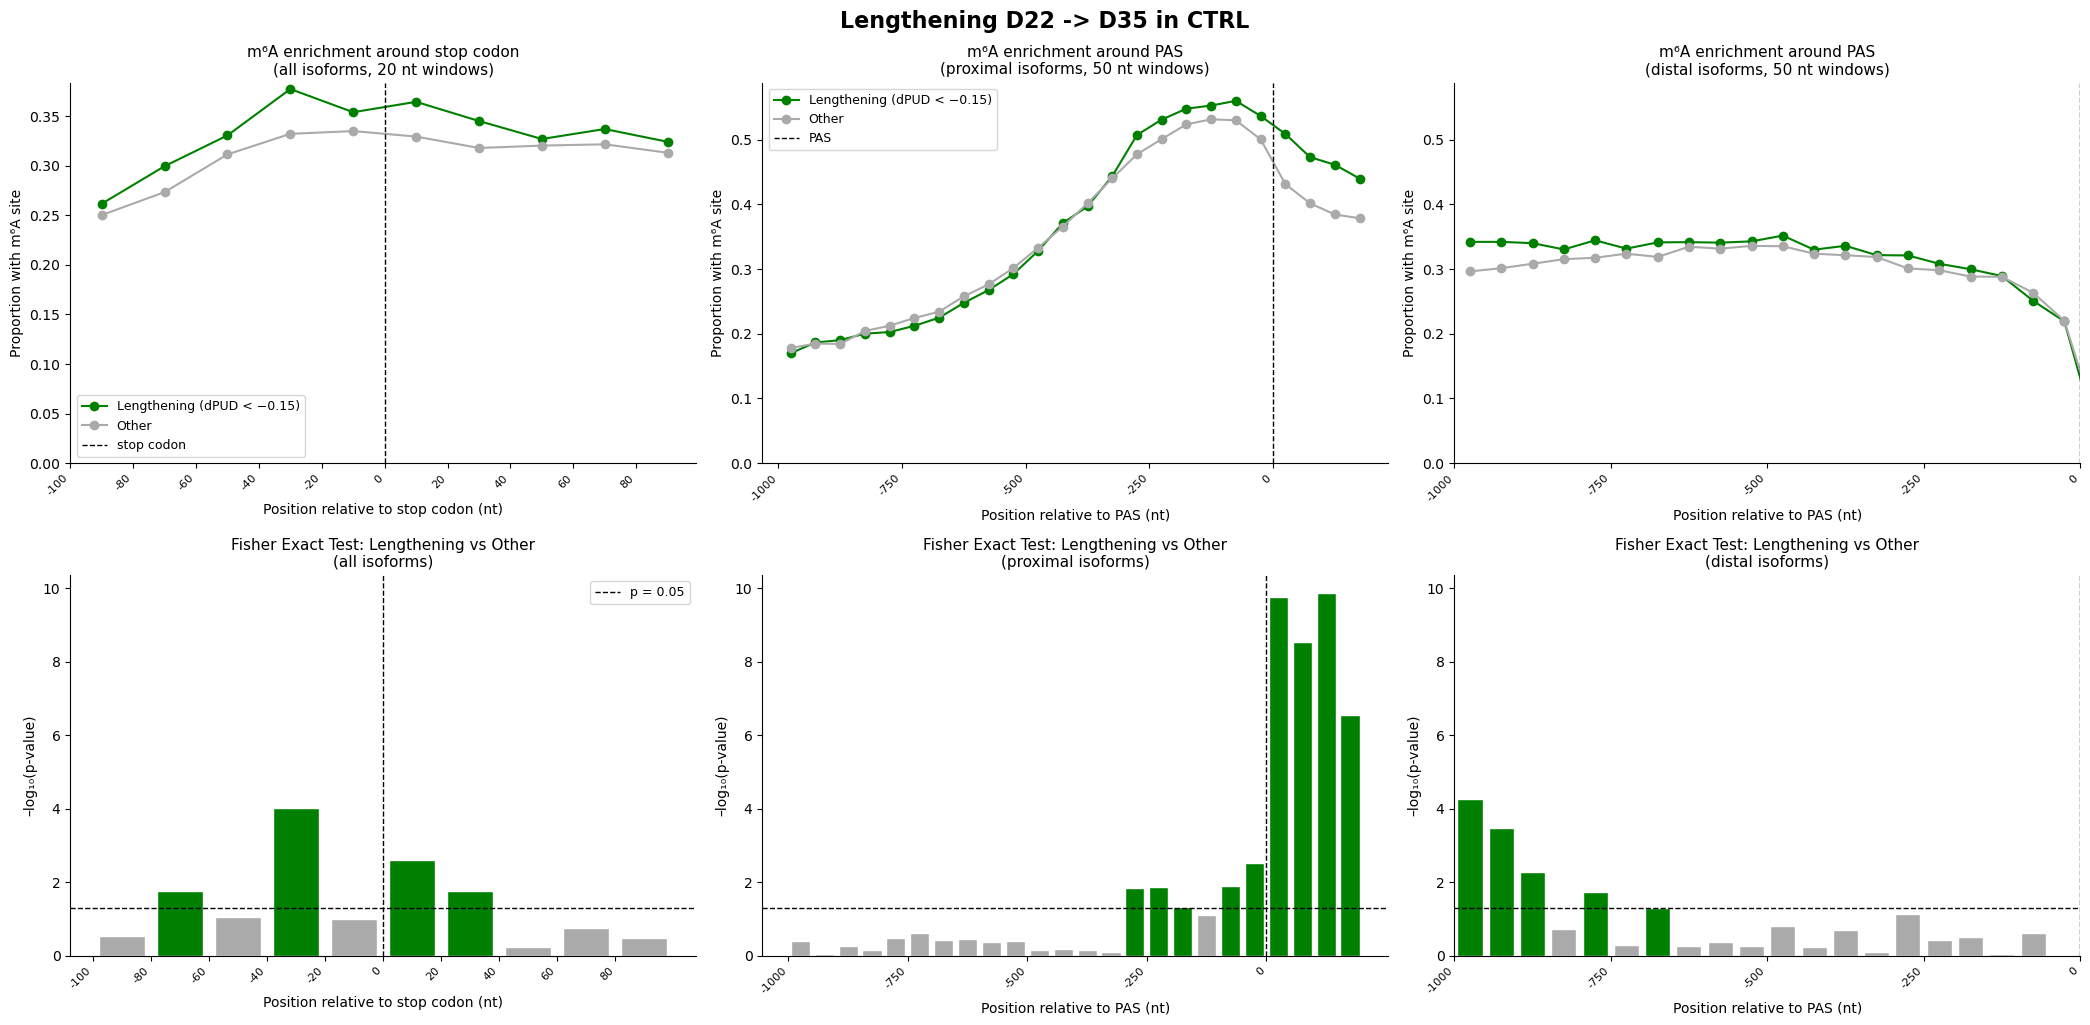

In [9]:
# Execute the function

fisher_sig_lengthening = pd.read_csv(f"{path_to_shift}/pairs_distals_D22_Nuclear_Wildtype_vs_D35_Nuclear_Wildtype.csv")

fisher_sig_lengthening = fisher_sig_lengthening[fisher_sig_lengthening['distal_id'].isin(table_of_pairs_longest['distal_id'])]

fisher_other = table_of_pairs_longest[~table_of_pairs_longest['distal_id'].isin(fisher_sig_lengthening['distal_id'])][["proximal_id", "distal_id"]]
fig, axes, pvalues = plot_m6a_profiles(fisher_sig_lengthening, fisher_other, annotation, m6a, stop_codon_lookup, WINDOW_SIZE=50)
plt.suptitle("Lengthening D22 -> D35 in CTRL", weight='bold', size=16, y=1.02)
save_figure(f"{figures_subfolder}/lineplot_proportion_with_m6A_around_PAS_nuclear_lengthened_D22_to_D35_CTRL.pdf", legend="Top: proportion of transcripts with >= 1 RMBase m6A site per window, around the stop codon (left; 20-nt windows from -100 to +100 nt, stop codon = first nt of the 3'UTR, shared by both isoforms of a pair; own y-scale) and around the PAS (50-nt windows from -1000 to +200 nt), for 3'UTR pairs lengthened from D22 to D35 in CTRL nuclei (pairs_distals_D22_Nuclear_Wildtype_vs_D35_Nuclear_Wildtype) (coloured) vs all other pairs (grey; longest distal isoform per proximal), proximal PAS (middle) and distal PAS (right, shown up to the PAS). Bottom: -log10(p) of a two-sided Fisher's exact test per window (coloured = p < 0.05, uncorrected; dashed line = p 0.05). The plot legend labels the group 'Lengthening' in every comparison.", bbox_inches='tight')

Annotation columns: ['seqname', 'source', 'feature', 'start', 'end', 'score', 'strand', 'frame', 'attribute', 'gene_id', 'transcript_id', 'uniqueID']
  chrom='seqname', transcript_id='transcript_id'

Transcripts in annotation: 40216


Computing profiles around the stop codon (all isoforms)...


Computing profiles around the PAS (proximal isoforms)...


Computing profiles around the PAS (distal isoforms)...


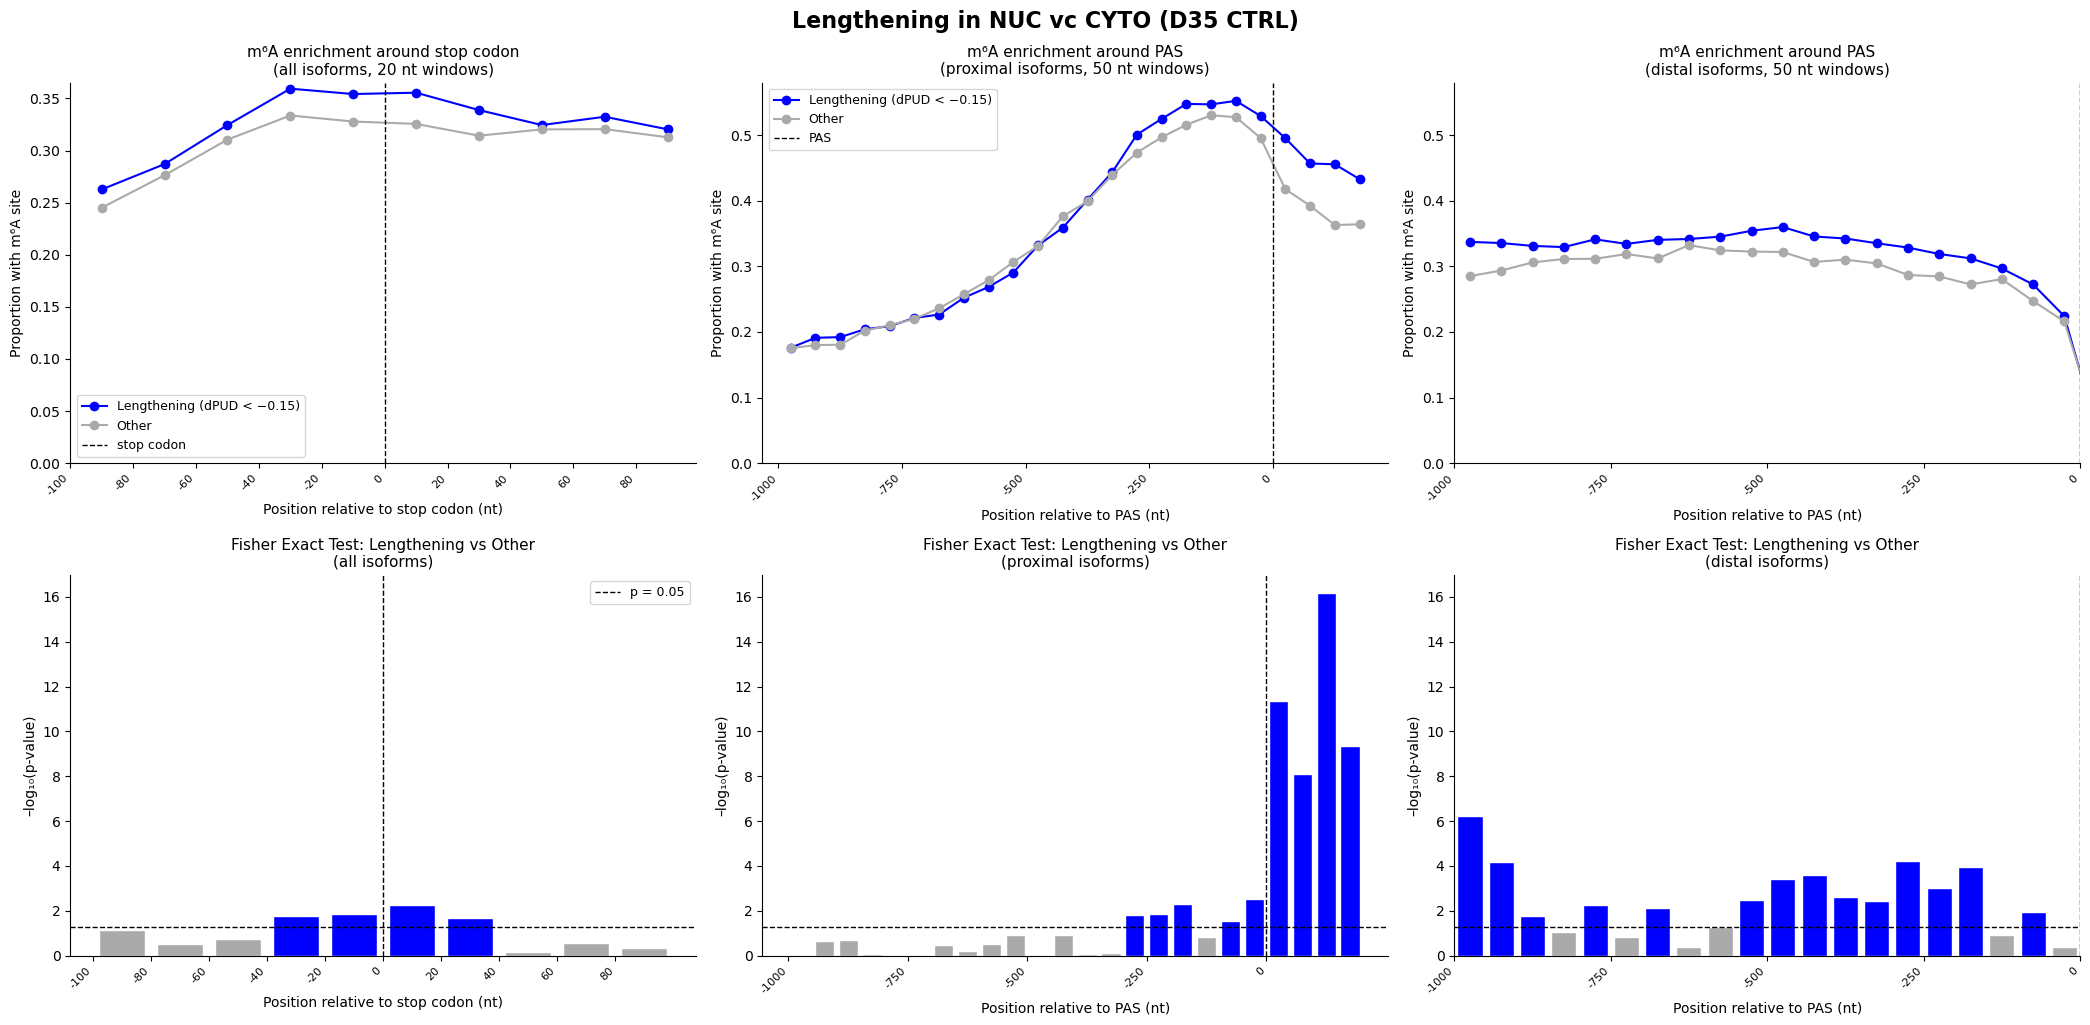

In [10]:
fisher_sig_lengthening = pd.read_csv(f"{path_to_shift}/pairs_proximals_D35_Nuclear_Wildtype_vs_D35_Cytoplasmic_Wildtype.csv")
fisher_sig_lengthening = fisher_sig_lengthening[fisher_sig_lengthening['distal_id'].isin(table_of_pairs_longest['distal_id'])]

fisher_other = table_of_pairs_longest[~table_of_pairs_longest['distal_id'].isin(fisher_sig_lengthening['distal_id'])][["proximal_id", "distal_id"]]
fig, axes, pvalues = plot_m6a_profiles(fisher_sig_lengthening, fisher_other, annotation, m6a, stop_codon_lookup, WINDOW_SIZE=50, color='blue')
plt.suptitle("Lengthening in NUC vc CYTO (D35 CTRL)", weight='bold', size=16, y=1.02)

save_figure(f"{figures_subfolder}/lineplot_proportion_with_m6A_around_PAS_longer_in_nucleus_D35_CTRL.pdf", legend="Top: proportion of transcripts with >= 1 RMBase m6A site per window, around the stop codon (left; 20-nt windows from -100 to +100 nt, stop codon = first nt of the 3'UTR, shared by both isoforms of a pair; own y-scale) and around the PAS (50-nt windows from -1000 to +200 nt), for 3'UTR pairs longer in the nucleus than in the cytoplasm at D35 in CTRL (proximal shift in the cytoplasm; pairs_proximals_D35_Nuclear_Wildtype_vs_D35_Cytoplasmic_Wildtype) (coloured) vs all other pairs (grey; longest distal isoform per proximal), proximal PAS (middle) and distal PAS (right, shown up to the PAS). Bottom: -log10(p) of a two-sided Fisher's exact test per window (coloured = p < 0.05, uncorrected; dashed line = p 0.05). The plot legend labels the group 'Lengthening' in every comparison.", bbox_inches='tight')

Annotation columns: ['seqname', 'source', 'feature', 'start', 'end', 'score', 'strand', 'frame', 'attribute', 'gene_id', 'transcript_id', 'uniqueID']
  chrom='seqname', transcript_id='transcript_id'

Transcripts in annotation: 40216


Computing profiles around the stop codon (all isoforms)...


Computing profiles around the PAS (proximal isoforms)...


Computing profiles around the PAS (distal isoforms)...


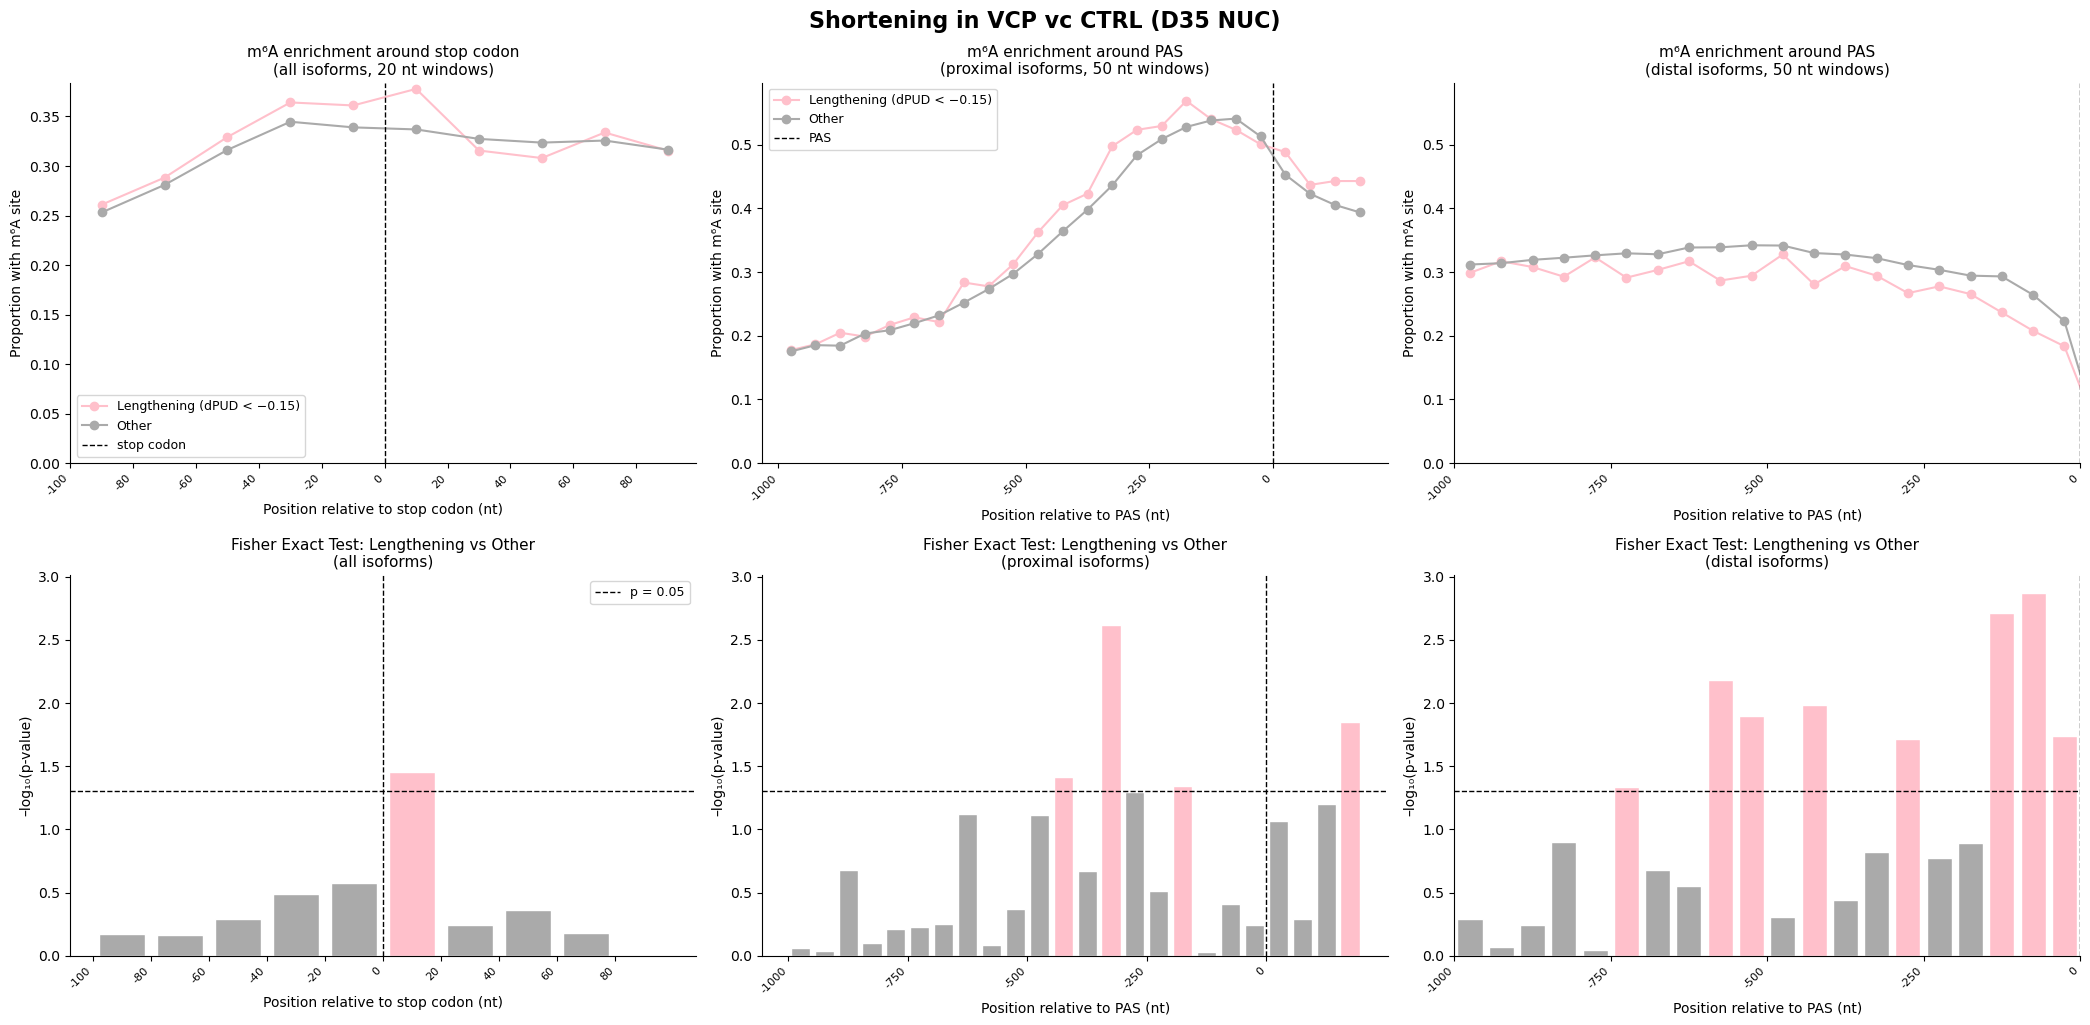

In [11]:
fisher_sig_lengthening = pd.read_csv(f"{path_to_shift}/pairs_proximals_D35_Nuclear_Wildtype_vs_D35_Nuclear_VCP.csv")
fisher_sig_lengthening = fisher_sig_lengthening[fisher_sig_lengthening['distal_id'].isin(table_of_pairs_longest['distal_id'])]

fisher_other = table_of_pairs_longest[~table_of_pairs_longest['distal_id'].isin(fisher_sig_lengthening['distal_id'])][["proximal_id", "distal_id"]]
fig, axes, pvalues = plot_m6a_profiles(fisher_sig_lengthening, fisher_other, annotation, m6a, stop_codon_lookup, WINDOW_SIZE=50, color='pink')
plt.suptitle("Shortening in VCP vc CTRL (D35 NUC)", weight='bold', size=16, y=1.02)

save_figure(f"{figures_subfolder}/lineplot_proportion_with_m6A_around_PAS_shortened_in_VCP_D35_nuclear.pdf", legend="Top: proportion of transcripts with >= 1 RMBase m6A site per window, around the stop codon (left; 20-nt windows from -100 to +100 nt, stop codon = first nt of the 3'UTR, shared by both isoforms of a pair; own y-scale) and around the PAS (50-nt windows from -1000 to +200 nt), for 3'UTR pairs shortened in VCP vs CTRL nuclei at D35 (pairs_proximals_D35_Nuclear_Wildtype_vs_D35_Nuclear_VCP) (coloured) vs all other pairs (grey; longest distal isoform per proximal), proximal PAS (middle) and distal PAS (right, shown up to the PAS). Bottom: -log10(p) of a two-sided Fisher's exact test per window (coloured = p < 0.05, uncorrected; dashed line = p 0.05). The plot legend labels the group 'Lengthening' in every comparison.", bbox_inches='tight')

## m6A enrichment normalized by A-content (controlling for the A-density confound)

m6A only occurs on an A, so if lengthening transcripts simply contain more A's overall (as the nucleotide-content profiles of `Figure_m6A_nucleotide_content.ipynb` show), the raw "proportion of transcripts with an m6A site" plot is expected to be higher for lengthening transcripts even with **no true difference in methylation propensity** — the raw metric conflates m6A regulation with A availability.

To control for this, instead of a per-transcript presence/absence proportion, this plots the **m6A site rate per A nucleotide**: for every 50 nt window, pool the total number of m6A sites and the total number of A bases across all transcripts in the group, and report `sites / n_A`. The Fisher exact test is run on the same normalized 2×2 table (`m6A sites` vs `non-methylated A's`), so it now asks whether A's are *more often methylated* in lengthening transcripts — not just whether there are more A's to begin with.

In [12]:
class FaidxFasta:
    """Minimal random-access FASTA reader using a samtools .fai index
    (no pysam/pyfaidx dependency available in this environment)."""
    def __init__(self, fasta_path):
        self.fh = open(fasta_path, 'rb')
        self.index = {}
        with open(fasta_path + '.fai') as f:
            for line in f:
                name, length, offset, linebases, linewidth = line.rstrip('\n').split('\t')
                self.index[name] = (int(length), int(offset), int(linebases), int(linewidth))

    def fetch(self, chrom, start, end):
        """0-based half-open [start, end) fetch."""
        if chrom not in self.index:
            return None
        length, offset, linebases, linewidth = self.index[chrom]
        start, end = max(0, start), min(length, end)
        if end <= start:
            return ''
        newline_len = linewidth - linebases
        start_line, start_col = divmod(start, linebases)
        end_line, end_col = divmod(end - 1, linebases)
        file_start = offset + start_line * linewidth + start_col
        file_end = offset + end_line * linewidth + end_col + 1
        self.fh.seek(file_start)
        raw = self.fh.read(file_end - file_start)
        if newline_len:
            raw = raw.replace(b'\n' * newline_len, b'')
        return raw.decode('ascii').upper()

_COMPLEMENT = str.maketrans('ACGTN', 'TGCAN')
def revcomp(seq):
    return seq.translate(_COMPLEMENT)[::-1]

hg38_fasta = FaidxFasta(f"{ANNOT_DIR}/UCSC/hg38.fa")


In [13]:
m6a_pos_global = m6a[['chrom', 'start']].drop_duplicates()
m6a_by_chrom_global = {c: np.sort(g['start'].values) for c, g in m6a_pos_global.groupby('chrom')}
def build_pas_lookup_seq(annotation_df):
    """One PAS position per transcript (max end for '+' strand, min start for '-')."""
    ann = annotation_df
    chrom_col = next((c for c in ['seqname', 'chrom', 'chr', 'Chromosome'] if c in ann.columns), ann.columns[0])
    tid_col   = next((c for c in ['transcript_id', 'transcript_name', 'name'] if c in ann.columns), None)

    ann_tx = ann[[chrom_col, 'start', 'end', 'strand', tid_col]].copy()
    ann_tx = ann_tx.groupby(tid_col).agg(
        chrom  = (chrom_col, 'first'),
        start  = ('start',   'min'),
        end    = ('end',     'max'),
        strand = ('strand',  'first')
    ).reset_index().rename(columns={tid_col: 'Isoform'})

    ann_tx['PAS'] = np.where(ann_tx['strand'] == '+', ann_tx['end'], ann_tx['start'])
    if not ann_tx['chrom'].iloc[0].startswith('chr'):
        ann_tx['chrom'] = 'chr' + ann_tx['chrom'].astype(str)
    return ann_tx[['Isoform', 'chrom', 'strand', 'PAS']]

pas_lookup = build_pas_lookup_seq(annotation)

def compute_m6a_per_A_profile(iso_df, isoform_col, ann_tx, fasta, m6a_by_chrom, window_lefts,
                               WINDOW_SIZE, wl_full=-1000, wr_full=200):
    """Per 50 nt window: total m6A sites and total A bases, pooled across all
    transcripts of the group (paired per-transcript so the two counts always
    come from the exact same window of the exact same sequence)."""
    matched = iso_df[[isoform_col]].drop_duplicates().rename(columns={isoform_col: 'Isoform'}).merge(ann_tx, on='Isoform', how='inner')
    n_windows = len(window_lefts)
    n_sites = np.zeros(n_windows, dtype=int)
    n_A = np.zeros(n_windows, dtype=int)
    n_used = 0
    for r in matched.itertuples(index=False):
        if r.strand == '+':
            seq = fasta.fetch(r.chrom, r.PAS + wl_full, r.PAS + wr_full)
        else:
            seq = fasta.fetch(r.chrom, r.PAS - wr_full, r.PAS - wl_full)
            if seq:
                seq = revcomp(seq)
        if not seq or len(seq) != (wr_full - wl_full):
            continue
        sites = m6a_by_chrom.get(r.chrom)
        n_used += 1
        for wi, wl in enumerate(window_lefts):
            wr = wl + WINDOW_SIZE
            bin_seq = seq[wl - wl_full: wr - wl_full]
            n_A[wi] += bin_seq.count('A')
            if sites is not None:
                lo, hi = (r.PAS + wl, r.PAS + wr) if r.strand == '+' else (r.PAS - wr, r.PAS - wl)
                n_sites[wi] += np.searchsorted(sites, hi) - np.searchsorted(sites, lo)
    return pd.DataFrame({
        'rel_pos': window_lefts,
        'n_sites': n_sites,
        'n_A': n_A,
        'rate_per_A': np.where(n_A > 0, n_sites / n_A, np.nan),
        'n_transcripts': n_used,
    })


In [14]:
def plot_m6a_per_A_profiles(sig_df, other_df, ann_tx, fasta, m6a_by_chrom, WINDOW_SIZE=50, color='green'):
    """Same 2x2 layout as plot_m6a_profiles, but the metric is m6A sites per A
    nucleotide (rate_per_A) instead of proportion of transcripts with a site,
    and the Fisher test compares (sites vs non-methylated A's)."""
    window_lefts = list(range(-1000, 200, WINDOW_SIZE))
    x_centers = [wl + WINDOW_SIZE / 2 for wl in window_lefts]

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    max_rate = 0
    max_pval = 0
    pvalues = {}
    for i, iso_type in enumerate(['proximal', 'distal']):
        col_name = f"{iso_type}_id"
        print(f"Computing m6A-per-A profile for {iso_type} isoforms...")
        prof_sig = compute_m6a_per_A_profile(sig_df, col_name, ann_tx, fasta, m6a_by_chrom, window_lefts, WINDOW_SIZE)
        prof_other = compute_m6a_per_A_profile(other_df, col_name, ann_tx, fasta, m6a_by_chrom, window_lefts, WINDOW_SIZE)

        max_rate = max(max_rate, prof_sig['rate_per_A'].max(), prof_other['rate_per_A'].max())

        # --- Top Row: m6A sites per A ---
        ax_top = axes[0, i]
        ax_top.plot(x_centers, prof_sig['rate_per_A'],   'o-', color=color,   linewidth=1.5, label='Lengthening (dPUD < −0.15)')
        ax_top.plot(x_centers, prof_other['rate_per_A'], 'o-', color='#aaaaaa', linewidth=1.5, label='Other')
        ax_top.axvline(0, color='black', linestyle='--', linewidth=1, label='PAS')

        ax_top.set_xlabel('Position relative to PAS (nt)', fontsize=10)
        ax_top.set_ylabel('m6A sites per A nucleotide', fontsize=10)
        ax_top.set_title(f'A-normalized m6A enrichment around PAS\n({iso_type} isoforms)', fontsize=11)
        ax_top.set_xticks(x_centers[::5])
        ax_top.set_xticklabels([str(window_lefts[j]) for j in range(0, len(window_lefts), 5)], rotation=45, ha='right', fontsize=8)
        if i == 0:
            ax_top.legend(fontsize=9)
        sns.despine(ax=ax_top)

        # --- Bottom Row: Fisher tests on (sites vs non-methylated A's) ---
        ax_bot = axes[1, i]
        pvals = []
        for j in range(len(window_lefts)):
            a = int(prof_sig['n_sites'].iloc[j])
            b = int(prof_sig['n_A'].iloc[j] - a)
            c = int(prof_other['n_sites'].iloc[j])
            d = int(prof_other['n_A'].iloc[j] - c)
            _, p = fisher_exact([[a, b], [c, d]], alternative='two-sided')
            pvals.append(p)
        pvalues[iso_type] = pd.DataFrame({'rel_pos': window_lefts, 'pval': -np.log10(pvals)})

        max_pval = max(max_pval, max(-np.log10(pvals)))

        neg_log10_p = [-np.log10(p) if p > 0 else 0 for p in pvals]
        colors = [color if p < 0.05 else '#aaaaaa' for p in pvals]

        ax_bot.bar(x_centers, neg_log10_p, width=WINDOW_SIZE * 0.8, color=colors, edgecolor='white')
        ax_bot.axvline(0, color='black', linestyle='--', linewidth=1)
        ax_bot.axhline(-np.log10(0.05), color='black', linestyle='--', linewidth=1, label='p = 0.05')

        ax_bot.set_xlabel('Position relative to PAS (nt)', fontsize=10)
        ax_bot.set_ylabel('–log₁₀(p-value)', fontsize=10)
        ax_bot.set_title(f'Fisher Exact Test (A-normalized): Lengthening vs Other\n({iso_type} isoforms)', fontsize=11)
        ax_bot.set_xticks(x_centers[::5])
        ax_bot.set_xticklabels([str(window_lefts[j]) for j in range(0, len(window_lefts), 5)], rotation=45, ha='right', fontsize=8)
        if i == 0:
            ax_bot.legend(fontsize=9)
        sns.despine(ax=ax_bot)

        if iso_type == 'distal':
            ax_top.set_xlim(-1000, 0)
            ax_bot.set_xlim(-1000, 0)

    axes[0, 0].set_ylim(0, max_rate * 1.05)
    axes[0, 1].set_ylim(0, max_rate * 1.05)
    axes[1, 0].set_ylim(0, max_pval * 1.05)
    axes[1, 1].set_ylim(0, max_pval * 1.05)
    plt.tight_layout()
    return fig, axes, pvalues

Computing m6A-per-A profile for proximal isoforms...


Computing m6A-per-A profile for distal isoforms...


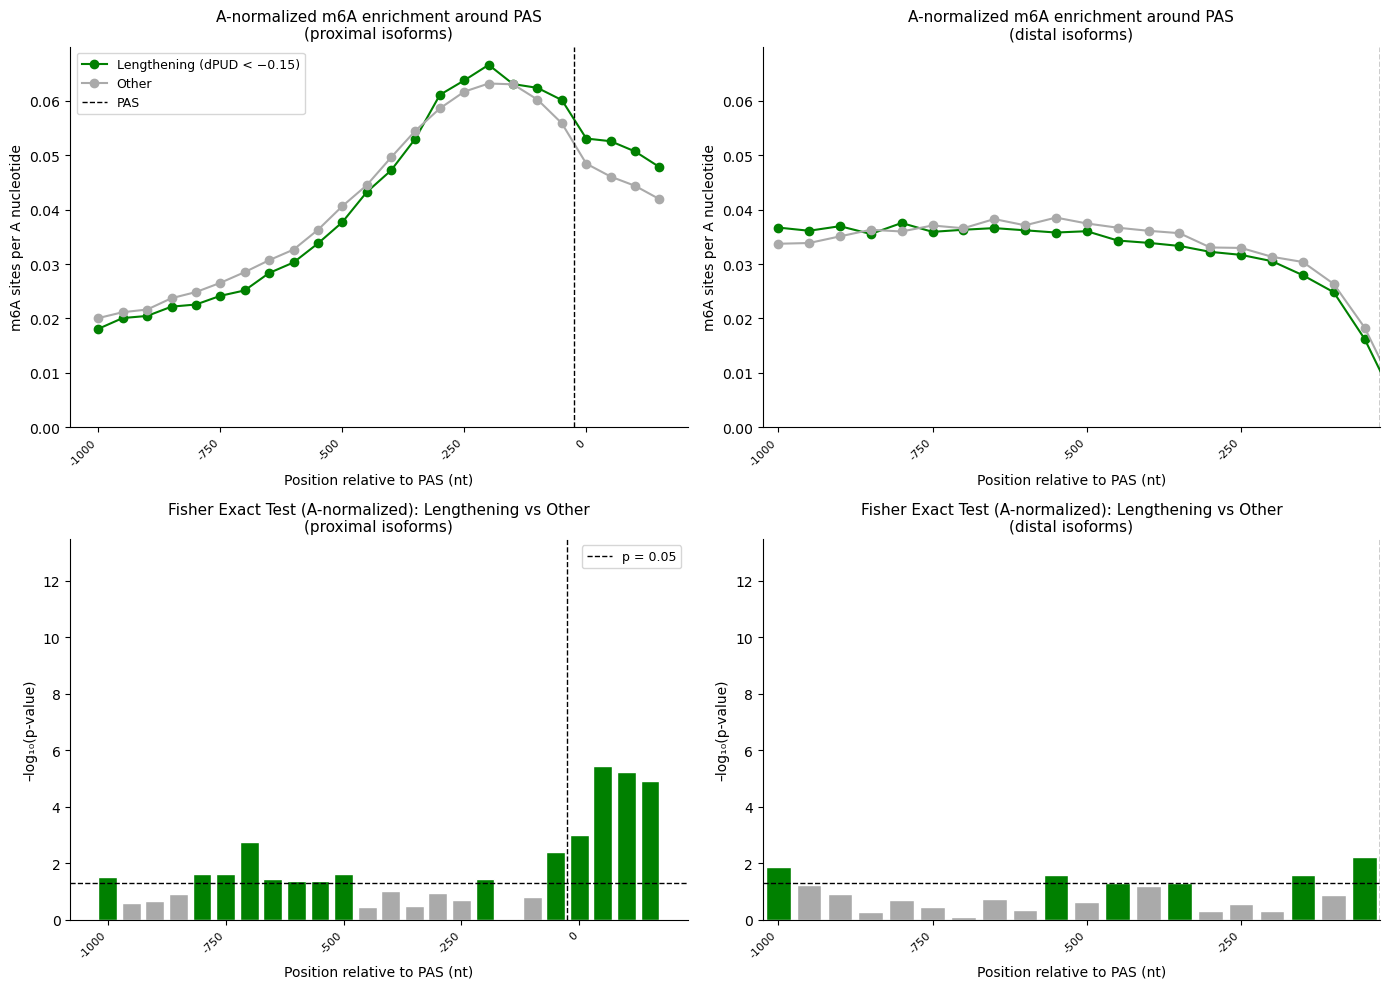

In [15]:
fisher_sig_lengthening = pd.read_csv(f"{path_to_shift}/pairs_distals_D22_Nuclear_Wildtype_vs_D35_Nuclear_Wildtype.csv")
fisher_sig_lengthening = fisher_sig_lengthening[fisher_sig_lengthening['distal_id'].isin(table_of_pairs_longest['distal_id'])]
fisher_other = table_of_pairs_longest[~table_of_pairs_longest['distal_id'].isin(fisher_sig_lengthening['distal_id'])][["proximal_id", "distal_id"]]

fig, axes, pvalues_m6a_per_A = plot_m6a_per_A_profiles(fisher_sig_lengthening, fisher_other, pas_lookup, hg38_fasta,
                                                         m6a_by_chrom_global, WINDOW_SIZE=50, color='green')

save_figure(f"{figures_subfolder}/lineplot_m6A_per_A_around_PAS_nuclear_lengthened_D22_to_D35_CTRL.pdf", legend="Top: m6A sites per A nucleotide in each 50-nt window from -1000 to +200 nt around the PAS (RMBase sites and A's of the hg38 sequence pooled over all transcripts; Fisher test on m6A sites vs non-methylated A's), for 3'UTR pairs lengthened from D22 to D35 in CTRL nuclei (pairs_distals_D22_Nuclear_Wildtype_vs_D35_Nuclear_Wildtype) (coloured) vs all other pairs (grey; longest distal isoform per proximal), proximal (left) and distal (right, shown up to the PAS) isoform. Bottom: -log10(p) of a two-sided Fisher's exact test per window (coloured = p < 0.05, uncorrected; dashed line = p 0.05). The plot legend labels the group 'Lengthening' in every comparison.",
            bbox_inches='tight')
plt.show()


Computing m6A-per-A profile for proximal isoforms...


Computing m6A-per-A profile for distal isoforms...


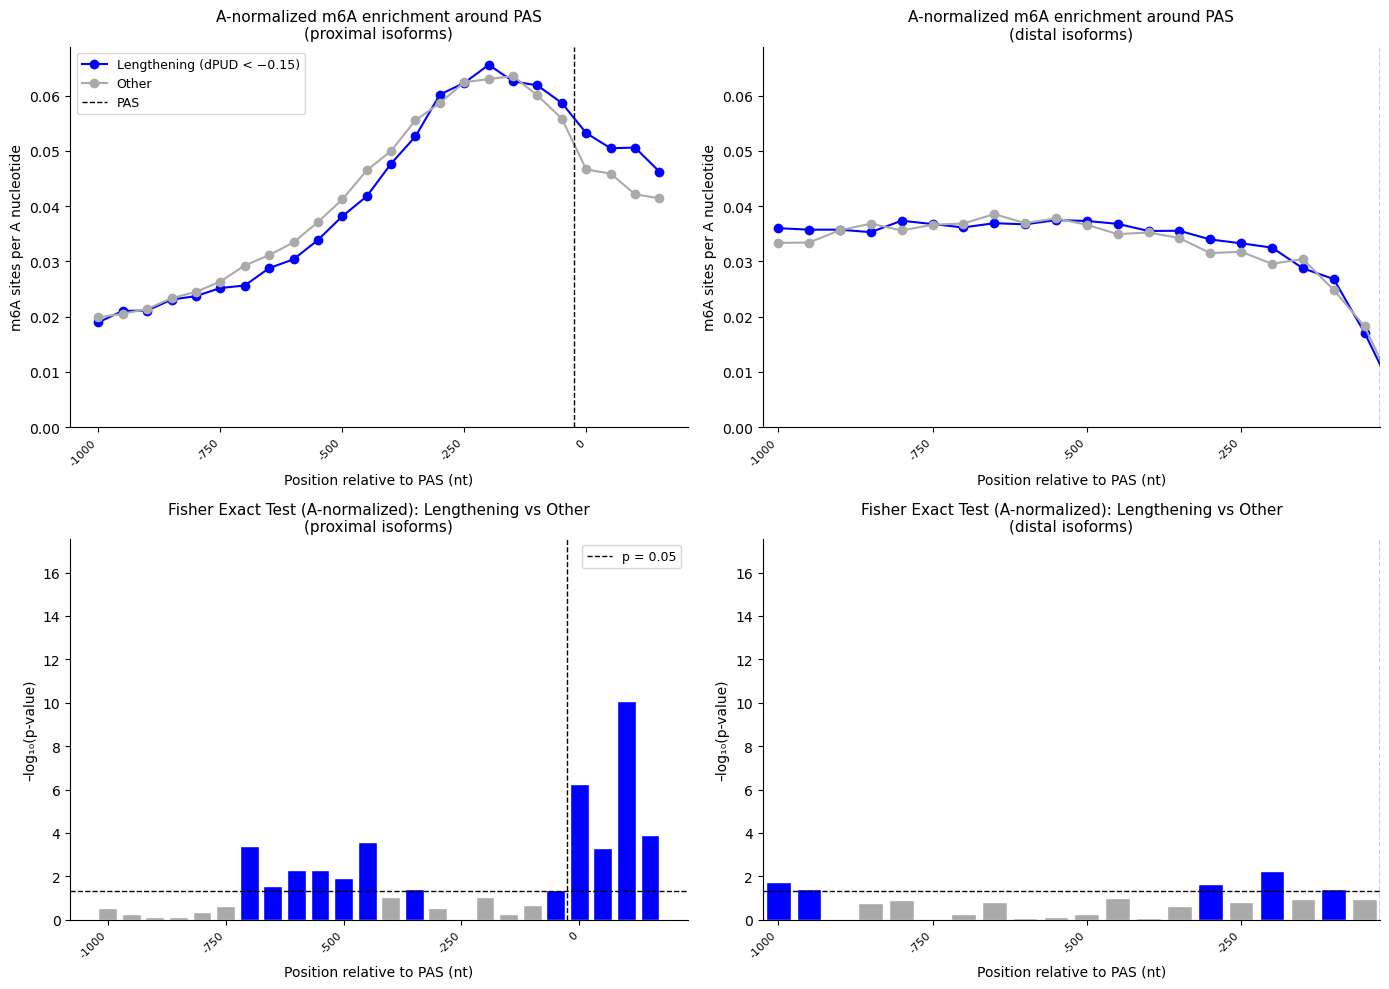

In [16]:
fisher_sig_lengthening = pd.read_csv(f"{path_to_shift}/pairs_proximals_D35_Nuclear_Wildtype_vs_D35_Cytoplasmic_Wildtype.csv")
fisher_sig_lengthening = fisher_sig_lengthening[fisher_sig_lengthening['distal_id'].isin(table_of_pairs_longest['distal_id'])]

fisher_other = table_of_pairs_longest[~table_of_pairs_longest['distal_id'].isin(fisher_sig_lengthening['distal_id'])][["proximal_id", "distal_id"]]

fig, axes, pvalues_m6a_per_A = plot_m6a_per_A_profiles(fisher_sig_lengthening, fisher_other, pas_lookup, hg38_fasta,
                                                         m6a_by_chrom_global, WINDOW_SIZE=50, color='blue')

save_figure(f"{figures_subfolder}/lineplot_m6A_per_A_around_PAS_longer_in_nucleus_D35_CTRL.pdf", legend="Top: m6A sites per A nucleotide in each 50-nt window from -1000 to +200 nt around the PAS (RMBase sites and A's of the hg38 sequence pooled over all transcripts; Fisher test on m6A sites vs non-methylated A's), for 3'UTR pairs longer in the nucleus than in the cytoplasm at D35 in CTRL (proximal shift in the cytoplasm; pairs_proximals_D35_Nuclear_Wildtype_vs_D35_Cytoplasmic_Wildtype) (coloured) vs all other pairs (grey; longest distal isoform per proximal), proximal (left) and distal (right, shown up to the PAS) isoform. Bottom: -log10(p) of a two-sided Fisher's exact test per window (coloured = p < 0.05, uncorrected; dashed line = p 0.05). The plot legend labels the group 'Lengthening' in every comparison.",
            bbox_inches='tight')
plt.show()

Computing m6A-per-A profile for proximal isoforms...


Computing m6A-per-A profile for distal isoforms...


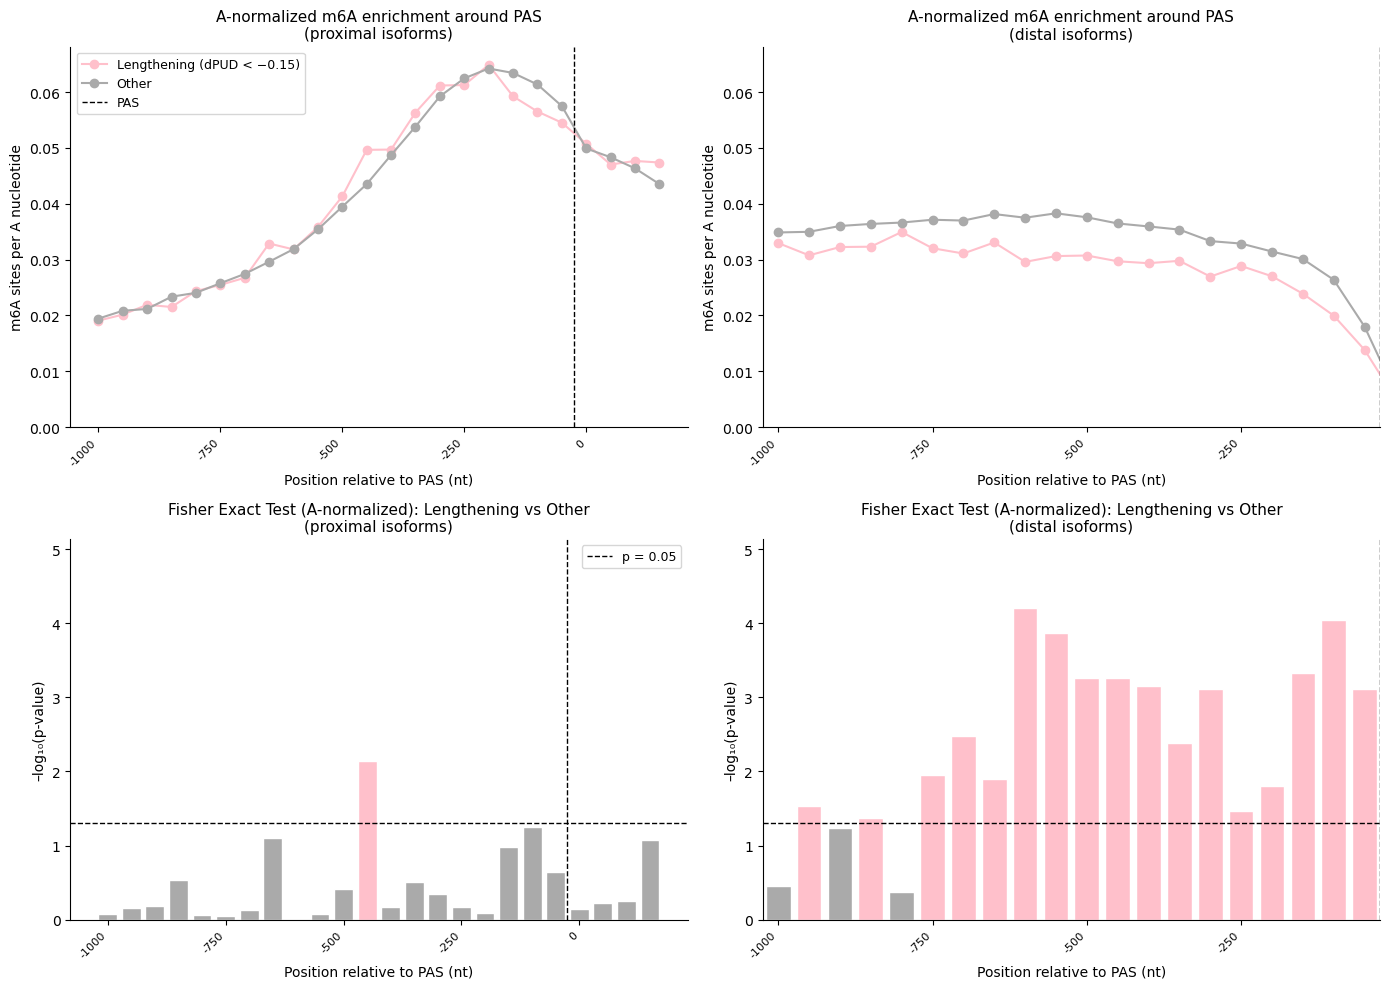

In [17]:
fisher_sig_lengthening = pd.read_csv(f"{path_to_shift}/pairs_proximals_D35_Nuclear_Wildtype_vs_D35_Nuclear_VCP.csv")
fisher_sig_lengthening = fisher_sig_lengthening[fisher_sig_lengthening['distal_id'].isin(table_of_pairs_longest['distal_id'])]

fisher_other = table_of_pairs_longest[~table_of_pairs_longest['distal_id'].isin(fisher_sig_lengthening['distal_id'])][["proximal_id", "distal_id"]]

fig, axes, pvalues_m6a_per_A = plot_m6a_per_A_profiles(fisher_sig_lengthening, fisher_other, pas_lookup, hg38_fasta,
                                                         m6a_by_chrom_global, WINDOW_SIZE=50, color='pink')

save_figure(f"{figures_subfolder}/lineplot_m6A_per_A_around_PAS_shortened_in_VCP_D35_nuclear.pdf", legend="Top: m6A sites per A nucleotide in each 50-nt window from -1000 to +200 nt around the PAS (RMBase sites and A's of the hg38 sequence pooled over all transcripts; Fisher test on m6A sites vs non-methylated A's), for 3'UTR pairs shortened in VCP vs CTRL nuclei at D35 (pairs_proximals_D35_Nuclear_Wildtype_vs_D35_Nuclear_VCP) (coloured) vs all other pairs (grey; longest distal isoform per proximal), proximal (left) and distal (right, shown up to the PAS) isoform. Bottom: -log10(p) of a two-sided Fisher's exact test per window (coloured = p < 0.05, uncorrected; dashed line = p 0.05). The plot legend labels the group 'Lengthening' in every comparison.",
            bbox_inches='tight')
plt.show()

## m6A machinery: expression over the MN differentiation time course (nuclear)

Erasers (FTO, ALKBH5), readers (YTHDF1-3, YTHDC1-2) and writers (VIRMA, RBM15, WTAP, METTL3, METTL14, CBLL1, RBM15B),
**nuclear fraction**, CTRL | VCP side by side.

Each cell = mean across the 4 replicates of the per-gene z-score of log2(expression + 1), z-scored across all nuclear
samples of both genotypes, so CTRL and VCP share one scale (same definition as the GO:0006406 heatmap of `Figure_3UTR_dynamics_over_time.ipynb`).
Genes kept in the given order (no clustering); white lines separate the eraser / reader / writer groups. Uses the helpers of
`utrals.go_expression`.

missing: []


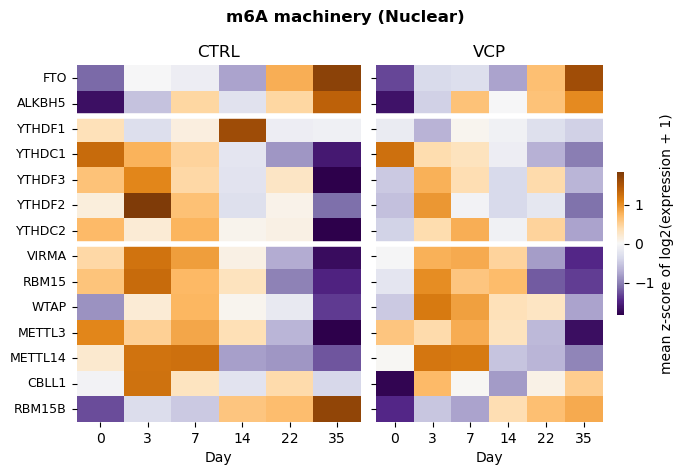

Genotype    WT                                 VCP                          \
Day         0     3     7     14    22    35    0     3     7     14    22   
gene                                                                         
FTO      -1.13 -0.01 -0.12 -0.78  0.79  1.74 -1.31 -0.35 -0.31 -0.78  0.67   
ALKBH5   -1.68 -0.55  0.45 -0.26  0.44  1.38 -1.65 -0.44  0.64 -0.01  0.64   
YTHDF1    0.35 -0.31  0.13  1.61 -0.12 -0.09 -0.15 -0.67  0.05 -0.08 -0.29   
YTHDC1    1.29  0.77  0.48 -0.22 -0.86 -1.59  1.24  0.39  0.33 -0.12 -0.68   
YTHDF3    0.64  1.07  0.44 -0.25  0.28 -2.21 -0.49  0.77  0.38 -0.36  0.40   
YTHDF2    0.15  1.85  0.65 -0.29  0.08 -1.10 -0.57  0.95 -0.06 -0.36 -0.20   
YTHDC2    0.71  0.20  0.75  0.06  0.10 -2.23 -0.43  0.40  0.80 -0.07  0.47   
VIRMA     0.44  1.22  0.91  0.11 -0.73 -1.71 -0.02  0.78  0.82  0.47 -0.82   
RBM15     0.62  1.30  0.72  0.32 -0.99 -1.50 -0.23  1.02  0.60  0.70 -1.20   
WTAP     -0.89  0.20  0.74  0.06 -0.18 -1.36 -0.49  1.17  0.89  0.36  0.29   
METTL3    1.06  0.51  0.85  0.36 -0.65 -1.97  0.61  0.40  0.80  0.33 -0.62   
METTL14   0.22  1.22  1.24 -0.80 -0.86 -1.23  0.02  1.19  1.17 -0.53 -0.64   
CBLL1    -0.06  1.23  0.31 -0.25  0.41 -0.37 -1.78  0.71  0.02 -0.83  0.09   
RBM15B   -1.27 -0.32 -0.49  0.61  0.68  1.70 -1.47 -0.52 -0.78  0.38  0.67   

Genotype        
Day         35  
gene            
FTO       1.59  
ALKBH5    1.04  
YTHDF1   -0.44  
YTHDC1   -1.02  
YTHDF3   -0.65  
YTHDF2   -1.10  
YTHDC2   -0.77  
VIRMA    -1.47  
RBM15    -1.35  
WTAP     -0.78  
METTL3   -1.69  
METTL14  -0.98  
CBLL1     0.53  
RBM15B    0.82

In [18]:
from utrals.expression import load_expression_metadata
from utrals.go_expression import gene_set_long, plot_pathway_heatmap

M6A_MACHINERY_COMPARTMENT = "Nuclear"
M6A_MACHINERY = ["FTO", "ALKBH5",
                 "YTHDF1", "YTHDC1", "YTHDF3", "YTHDF2", "YTHDC2",
                 "VIRMA", "RBM15", "WTAP", "METTL3", "METTL14", "CBLL1", "RBM15B"]
M6A_MACHINERY_BREAKS = ["ALKBH5", "YTHDC2"]  # last eraser, last reader

df_genes, meta_genes = load_expression_metadata(
    f"{PROJECT_DIR}/MN_diff/results/genes_preprocessing/df_genes_filtered_normalized.csv")
machinery_long = gene_set_long(M6A_MACHINERY, df_genes, meta_genes, compartment=M6A_MACHINERY_COMPARTMENT)
print("missing:", [g for g in M6A_MACHINERY if g not in df_genes.index])

fig, axes, machinery_mat_z = plot_pathway_heatmap(
    machinery_long, metric="zscore", row_order=M6A_MACHINERY, row_breaks=M6A_MACHINERY_BREAKS, cmap="PuOr_r",
    title=f"m6A machinery ({M6A_MACHINERY_COMPARTMENT})", figsize=(7, 4.8), ytick_size=9,
)
save_figure(f"../Figures/Figure_m6A/m6A_machinery_expression/heatmap_m6A_machinery_gene_zscore_{M6A_MACHINERY_COMPARTMENT}_CTRL_vs_VCP.pdf",
            legend=f"Expression of the m6A machinery over MN differentiation ({M6A_MACHINERY_COMPARTMENT.lower()} fraction), "
                   "CTRL (left) and VCP (right): erasers (FTO, ALKBH5), readers (YTHDF1, YTHDC1, YTHDF3, YTHDF2, YTHDC2) and "
                   "writers (VIRMA, RBM15, WTAP, METTL3, METTL14, CBLL1, RBM15B), separated by white lines. Each cell = mean "
                   "across replicates of the per-gene z-score of log2(normalised counts + 1), computed across all "
                   "nuclear samples of both genotypes (shared colour scale, clipped at the 98th percentile of |z|). Rows "
                   "in fixed order (no clustering). No statistical test.")
plt.show()
machinery_mat_z.round(2)